# Lab 6 — Localization: model vs real odometry (digits 4 0)

The robot drives the digits **4** and **0** through 9 waypoints with a go-to-goal controller, steering by
its own odometry, and logs `x,y,time` (m, m, ms) every loop pass. The same program runs in the TRIK
simulator (`Rahmonjon_trajectory_sim.qrs`) and on the robot (`Rahmonjon_trajectory_real.qrs`); only `r`, `B`
and the log name differ.

Odometry (midpoint form, wheel angles from the encoders in degrees, left = E4, right = E3):
`dL = r·Δenc_L·π/180`, `dR = r·Δenc_R·π/180`, `ds = (dL + dR)/2`, `dh = (dR − dL)/B`,
`x += ds·cos(h + dh/2)`, `y += ds·sin(h + dh/2)`, `h = wrap(h + dh)`.

In [1]:
import os
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

try:                                # in Colab: upload the txt files
    from google.colab import files  # file work module
    uploaded = files.upload()       # select odometry_data_sim.txt and odometry_data_real.txt
except ImportError:                 # local Jupyter: files next to the notebook
    pass

# Planned waypoints (m), copied from the init block; (0, 0) is the start
wx = [0, 0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.8, 0.8, 0.5]
wy = [0, -0.3, -0.3, 0, -0.6, -0.6, 0, 0, -0.6, -0.6]
wp = np.c_[wx, wy]

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt', delimiter=',', unpack=True)
have_real = os.path.exists('odometry_data_real.txt')
if have_real:
    x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)
print(f'sim:  {len(t_s)} samples, {(t_s[-1] - t_s[0]) / 1000:.1f} s')
if have_real:
    print(f'real: {len(t_r)} samples, {(t_r[-1] - t_r[0]) / 1000:.1f} s')

sim:  2062 samples, 41.5 s
real: 372 samples, 23.2 s


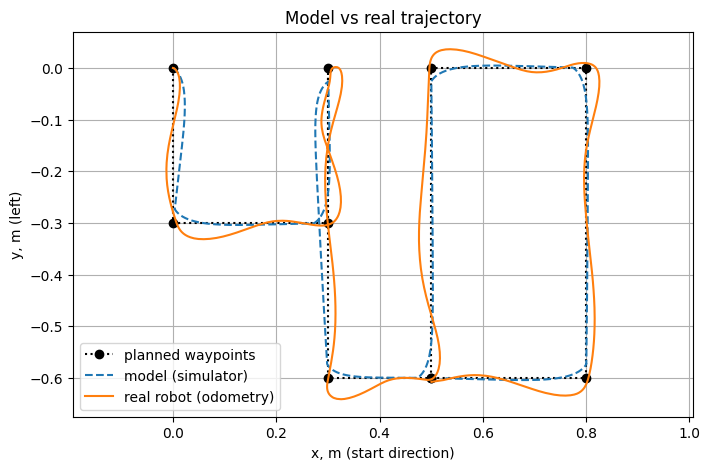

In [2]:
# 1. Planned path vs simulated vs real
plt.figure(figsize=(8, 5))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
if have_real:
    plt.plot(x_r, y_r, label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, m (start direction)'); plt.ylabel('y, m (left)')
plt.title('Model vs real trajectory')
plt.show()

In [3]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s)
miss_r = waypoint_miss(x_r, y_r) if have_real else np.full(len(wp), np.nan)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i:2d} ({wp[i, 0]:5.2f}, {wp[i, 1]:5.2f}): sim {ms * 100:4.1f} cm | real {mr * 100:4.1f} cm')

Waypoint  0 ( 0.00,  0.00): sim  0.0 cm | real  0.0 cm
Waypoint  1 ( 0.00, -0.30): sim  2.1 cm | real  0.7 cm
Waypoint  2 ( 0.30, -0.30): sim  1.7 cm | real  0.4 cm
Waypoint  3 ( 0.30,  0.00): sim  2.7 cm | real  0.7 cm
Waypoint  4 ( 0.30, -0.60): sim  1.8 cm | real  0.4 cm
Waypoint  5 ( 0.50, -0.60): sim  1.9 cm | real  0.3 cm
Waypoint  6 ( 0.50,  0.00): sim  1.8 cm | real  0.4 cm
Waypoint  7 ( 0.80,  0.00): sim  1.8 cm | real  0.9 cm
Waypoint  8 ( 0.80, -0.60): sim  1.8 cm | real  0.5 cm
Waypoint  9 ( 0.50, -0.60): sim  1.9 cm | real  0.3 cm


## Error between model and real

The Lab 6 README compares the two runs at equal **time**. The simulated robot is slower than the real
one, so that curve mostly shows the speed difference. The second plot compares them at equal
**distance travelled**, which shows how different the two paths are in shape.

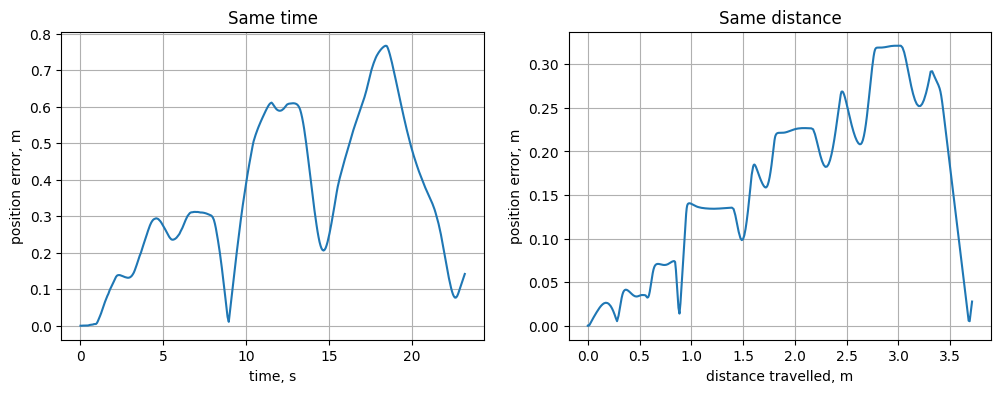

Final odometry difference (sim vs real): 0.028 m
Max error: same time 0.767 m | same distance 0.321 m
Path length: sim 3.32 m | real 3.71 m


In [4]:
def arc(x, y):
    return np.concatenate([[0], np.cumsum(np.hypot(np.diff(x), np.diff(y)))])

if have_real:
    t_s0, t_r0 = t_s - t_s[0], t_r - t_r[0]
    err_t = np.hypot(x_r - np.interp(t_r0, t_s0, x_s), y_r - np.interp(t_r0, t_s0, y_s))

    s_s, s_r = arc(x_s, y_s), arc(x_r, y_r)
    keep = np.concatenate([[True], np.diff(s_s) > 0])       # drop samples where the robot stood still
    err_d = np.hypot(x_r - np.interp(s_r, s_s[keep], x_s[keep]), y_r - np.interp(s_r, s_s[keep], y_s[keep]))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(t_r0 / 1000, err_t); ax[0].set(xlabel='time, s', ylabel='position error, m', title='Same time')
    ax[1].plot(s_r, err_d); ax[1].set(xlabel='distance travelled, m', ylabel='position error, m', title='Same distance')
    for a in ax: a.grid(True)
    plt.show()
    print(f'Final odometry difference (sim vs real): {np.hypot(x_r[-1] - x_s[-1], y_r[-1] - y_s[-1]):.3f} m')
    print(f'Max error: same time {err_t.max():.3f} m | same distance {err_d.max():.3f} m')
    print(f'Path length: sim {s_s[-1]:.2f} m | real {s_r[-1]:.2f} m')

## Loop timing

The simulator runs the loop every 20 ms (the Timer block). On the robot the loop is slower, because the
diagram runtime and Write To File take time, so the controller reacts later.

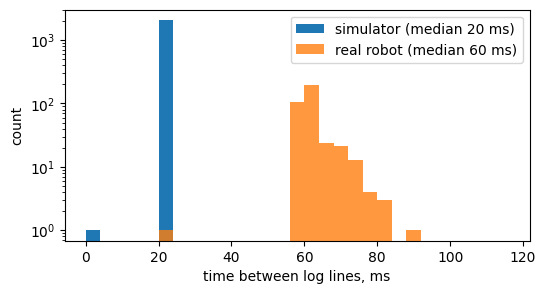

In [5]:
plt.figure(figsize=(6, 3))
bins = np.arange(0, 120, 4)
plt.hist(np.diff(t_s), bins, label=f'simulator (median {np.median(np.diff(t_s)):.0f} ms)')
if have_real:
    plt.hist(np.diff(t_r), bins, alpha=.8, label=f'real robot (median {np.median(np.diff(t_r)):.0f} ms)')
plt.yscale('log'); plt.xlabel('time between log lines, ms'); plt.ylabel('count'); plt.legend()
plt.show()

## Original vs fixed program on the real robot

The original program (`original_trajectory_real_measured_correction.qrs`) drove the shape **by time**
(fixed power for fixed milliseconds) and only logged its odometry. If you still have its log, save it as
`original_run_odometry_data.txt` next to this notebook to compare speed and stalls. Its odometry used
`r = 0.034`, `B = 0.155` and M3 = left, so compare timing, not the shape.

In [6]:
if have_real and os.path.exists('original_run_odometry_data.txt'):
    x_o, y_o, t_o = np.loadtxt('original_run_odometry_data.txt', delimiter=',', unpack=True)
    for name, (x, y, t) in {'original': (x_o, y_o, t_o), 'fixed': (x_r, y_r, t_r)}.items():
        dt = np.diff(t) / 1000
        speed = np.hypot(np.diff(x), np.diff(y)) / np.maximum(dt, 1e-3)
        print(f'{name:8s}: {t[-1] / 1000:5.1f} s, standing still (< 1 cm/s) {dt[speed < 0.01].sum():4.1f} s')
else:
    print('no original_run_odometry_data.txt - skipped')

no original_run_odometry_data.txt - skipped


## Measured end point (tape)

Mark the start point (between the wheels) and the start direction on the floor. After the run measure
the real end point in that frame: **x** along the start direction, **y** to the left (m; to the right is
negative). The robot's odometry believes it is at the last log line.

In [7]:
x_meas, y_meas = None, None   # <- fill in after the real run, metres

print(f'last waypoint:        ({wx[-1]:.3f}, {wy[-1]:.3f}) m')
print(f'simulator odometry:   ({x_s[-1]:.3f}, {y_s[-1]:.3f}) m')
if have_real:
    print(f'real odometry (log):  ({x_r[-1]:.3f}, {y_r[-1]:.3f}) m')
if have_real and x_meas is not None:
    print(f'measured with tape:   ({x_meas:.3f}, {y_meas:.3f}) m')
    print(f'odometry error (log vs tape): {np.hypot(x_r[-1] - x_meas, y_r[-1] - y_meas):.3f} m')

last waypoint:        (0.500, -0.600) m
simulator odometry:   (0.528, -0.601) m
real odometry (log):  (0.501, -0.608) m


## Discussion (3–6 sentences)

Because of an asymmetry in wheels the lines are curved and my program tries to fix it by ocuntering it.